# Fase 4: Visualización y comunicación de resultados

## Proyecto: Factores asociados a la permanencia operativa de startups de Y Combinator

## Introducción

Esta cuarta fase del proyecto tiene como propósito comunicar y analizar los resultados obtenidos a partir del procesamiento y estructuración de los datos desarrollados en las fases anteriores. Para ello, se utilizará el dataset procesado y validado durante la Fase 3, evitando repetir las operaciones de limpieza y transformación previamente implementadas.

Mediante herramientas de visualización de datos, se buscará identificar patrones, distribuciones y características relevantes de las startups pertenecientes al dataset de Y Combinator, relacionando los resultados obtenidos con la problemática y los objetivos definidos inicialmente en la Fase 1.

## Objetivo de la Fase 4

Comunicar los principales hallazgos del proyecto mediante visualizaciones analíticas, evaluando si las diferencias entre startups de IA y tradicionales se mantienen dentro de rangos comparables de antigüedad, y examinando cómo la permanencia operativa, la contratación y la adopción de IA varían entre industrias.

## Alcance

Esta fase contempla la integración de los datos procesados, la validación de su estructura para el análisis visual, la elaboración de visualizaciones, la interpretación de resultados, la identificación de limitaciones y la formulación de conclusiones.

El análisis se realizará sobre los datos resultantes de la Fase 3, manteniendo la coherencia metodológica y técnica con las etapas previas del proyecto.

In [1]:
# Librerías para análisis y visualización
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

#  Carga y verificación del conjunto procesado


In [2]:
def localizar_raiz():

    carpeta_actual = Path.cwd()

    if carpeta_actual.name in {
        "F1",
        "F2",
        "F3",
        "F4"
    }:
        return carpeta_actual.parent

    return carpeta_actual


RAIZ = localizar_raiz()

print("Raíz del proyecto:")
print(RAIZ)

Raíz del proyecto:
C:\Users\Casti\U-Andres-Bello\U-Andres-Bello


In [3]:
def localizar_raiz():
    carpeta_actual = Path.cwd()

    if carpeta_actual.name in {"F1", "F2", "F3", "F4"}:
        return carpeta_actual.parent

    return carpeta_actual


RAIZ = localizar_raiz()

DIR_PROCESADO = RAIZ / "data" / "processed"
DIR_FIGURAS = RAIZ / "F4" / "figuras"
DIR_DOCS = RAIZ / "docs"

DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_DOCS.mkdir(parents=True, exist_ok=True)

print("Raíz del proyecto:", RAIZ)
print("Datos procesados:", DIR_PROCESADO)
print("Directorio de figuras:", DIR_FIGURAS)

Raíz del proyecto: C:\Users\Casti\U-Andres-Bello\U-Andres-Bello
Datos procesados: C:\Users\Casti\U-Andres-Bello\U-Andres-Bello\data\processed
Directorio de figuras: C:\Users\Casti\U-Andres-Bello\U-Andres-Bello\F4\figuras


In [4]:
RUTA_DATASET = "../data/y-combinator-companies.csv"

df_original = pd.read_csv(
    RUTA_DATASET
)

df_original.head()

,company_id,name,yc_slug,yc_url,batch,batch_season,batch_year,batch_code,years_since_batch,status,...,website,domain,domain_tld,website_status,website_live,website_final_domain,website_redirects_offsite,checked_at,batch_size,batch_active_rate
0,32165,Rote,rote,https://www.ycombinator.com/companies/rote,Winter 2027,Winter,2027.0,W27,-1.0,Active,...,https://tryrote.com/,tryrote.com,tryrote.com,200.0,True,tryrote.com,False,2026-08-27,1,1.0
1,35290,Antropi Robotics,antropi-robotics,https://www.ycombinator.com/companies/antropi-...,Fall 2026,Fall,2026.0,F26,0.0,Active,...,https://www.antropi.world/,antropi.world,antropi.world,200.0,True,antropi.world,False,2026-08-27,23,1.0
2,35058,Capveon,capveon,https://www.ycombinator.com/companies/capveon,Fall 2026,Fall,2026.0,F26,0.0,Active,...,https://capveon.ai,capveon.ai,capveon.ai,200.0,True,capveon.ai,False,2026-08-27,23,1.0
3,31461,Collar,collar,https://www.ycombinator.com/companies/collar,Fall 2026,Fall,2026.0,F26,0.0,Active,...,https://usecollarai.com,usecollarai.com,usecollarai.com,200.0,True,usecollarai.com,False,2026-08-27,23,1.0
4,36084,Covera,covera,https://www.ycombinator.com/companies/covera,Fall 2026,Fall,2026.0,F26,0.0,Active,...,https://www.covera-agents.com/,covera-agents.com,covera-agents.com,200.0,True,covera-agents.com,False,2026-08-27,23,1.0


In [14]:
columnas_requeridas = {
    "name",
    "is_operating",
    "is_hiring",
    "status",
    "is_ai",
    "team_size",
    "industry",
    "hq_country",
    "years_since_batch"
}

columnas_faltantes = (
    columnas_requeridas -
    set(df.columns)
)

assert not columnas_faltantes, (
    f"Faltan columnas requeridas: {sorted(columnas_faltantes)}"
)

assert df.isna().sum().sum() == 0
assert "Y Combinator" not in df["name"].values

print("Dimensiones:", df.shape)
print("Total de valores nulos:", df.isna().sum().sum())
print("Contrato de datos verificado correctamente.")

Dimensiones: (6193, 10)
Total de valores nulos: 0
Contrato de datos verificado correctamente.


In [15]:
#se utiliza archivo procesado
DIR_PROCESADO = RAIZ / "data" / "processed"

RUTA_PROCESADO = (
    DIR_PROCESADO /
    "startups_procesadas.csv"
)

print(RUTA_PROCESADO.exists())

True


# Preparación de variables para el análisis
La antigüedad se agrupa en tramos para comparar empresas con tiempos de exposición similares. Esta segmentación evita atribuir directamente a la IA diferencias que podrían deberse a que las startups tecnológicas se concentran en batches más recientes.

In [16]:
df["tramo_antiguedad"] = pd.cut(
    df["years_since_batch"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=[
        "0-2 años",
        "3-5 años",
        "6-10 años",
        "11+ años"
    ]
)

df["tipo_startup"] = df["is_ai"].map({
    True: "IA",
    False: "Tradicional"
})

df[
    [
        "tipo_startup",
        "tramo_antiguedad",
        "industry",
        "is_operating",
        "is_hiring"
    ]
].head()

,tipo_startup,tramo_antiguedad,industry,is_operating,is_hiring
0,Tradicional,0-2 años,B2B,True,False
1,Tradicional,0-2 años,Industrials,True,False
2,Tradicional,0-2 años,Government,True,False
3,IA,0-2 años,B2B,True,False
4,Tradicional,0-2 años,Fintech,True,True


# Pregunta 1

¿Existe una diferencia en la permanencia operativa entre startups relacionadas con inteligencia artificial y startups tradicionales?


In [37]:
permanencia_ia = (
    df
    .groupby("is_ai")["is_operating"]
    .mean()
    .reset_index()
)

permanencia_ia

,is_ai,is_operating
0,False,0.652798
1,True,0.847763


In [38]:
permanencia_ia["grupo"] = (
    permanencia_ia["is_ai"]
    .map({
        True: "IA",
        False: "Tradicional"
    })
)

permanencia_ia

,is_ai,is_operating,grupo
0,False,0.652798,Tradicional
1,True,0.847763,IA


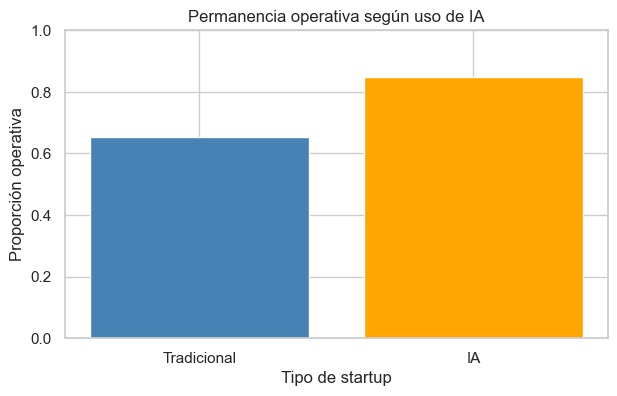

In [39]:
plt.figure(figsize=(7,4))

plt.bar(
    permanencia_ia["grupo"],
    permanencia_ia["is_operating"],
    color=["steelblue", "orange"]
)

plt.ylabel(
    "Proporción operativa"
)

plt.xlabel(
    "Tipo de startup"
)

plt.title(
    "Permanencia operativa según uso de IA"
)

plt.ylim(0, 1)

plt.show()

In [40]:
ia = permanencia_ia.loc[
    permanencia_ia["grupo"] == "IA",
    "is_operating"
].iloc[0]

tradicional = permanencia_ia.loc[
    permanencia_ia["grupo"] == "Tradicional",
    "is_operating"
].iloc[0]

print(
    f"IA: {ia:.2%}"
)

print(
    f"Tradicional: {tradicional:.2%}"
)


IA: 84.78%
Tradicional: 65.28%


### Análisis Figura 1: Las startups de IA presentan una mayor permanencia operativa

Las startups relacionadas con inteligencia artificial presentan una permanencia operativa de 84,78 %, mientras que las startups tradicionales alcanzan un 65,28 %. Esta diferencia sugiere una asociación positiva entre el uso de tecnologías de IA y la condición operativa actual de las empresas. Sin embargo, este resultado debe interpretarse con cautela, ya que variables como la antigüedad de las startups podrían influir en la diferencia observada.

# Pregunta 2
¿Cómo se relaciona la antigüedad de las startups con su permanencia operativa?

In [41]:
df["tramo_antiguedad"] = pd.cut(

    df["years_since_batch"],

    bins=[-1, 2, 5, 10, 20],

    labels=[
        "0-2 años",
        "3-5 años",
        "6-10 años",
        "11+ años"
    ]

)

In [42]:
antiguedad = (

    df
    .groupby("tramo_antiguedad")
    ["is_operating"]
    .mean()
    .reset_index()

)

antiguedad

C:\Users\Casti\AppData\Local\Temp\ipykernel_25604\3297545561.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("tramo_antiguedad")


,tramo_antiguedad,is_operating
0,0-2 años,0.961394
1,3-5 años,0.757151
2,6-10 años,0.552258
3,11+ años,0.284934


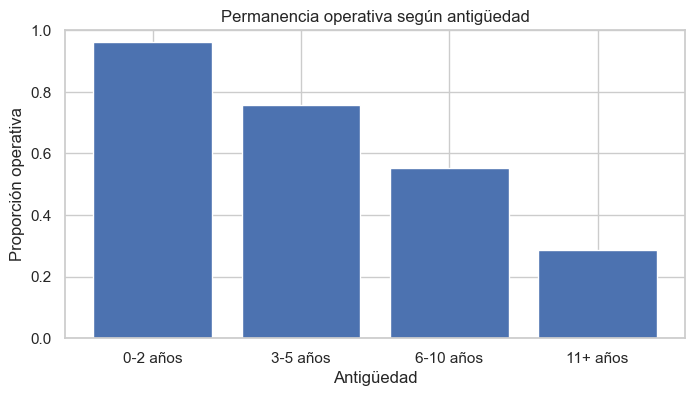

In [43]:
plt.figure(figsize=(8,4))

plt.bar(

    antiguedad["tramo_antiguedad"],
    antiguedad["is_operating"]

)

plt.ylim(0,1)

plt.xlabel(
    "Antigüedad"
)

plt.ylabel(
    "Proporción operativa"
)

plt.title(
    "Permanencia operativa según antigüedad"
)

plt.show()

### Análisis Figura 2: La permanencia operativa disminuye en startups más antiguas

La permanencia operativa disminuye de forma sostenida a medida que aumenta la antigüedad de las startups. Mientras las empresas con entre 0 y 2 años desde su participación en Y Combinator registran tasas cercanas al 96 %, las empresas con más de 11 años presentan valores cercanos al 29 %. Esto indica que la antigüedad constituye uno de los factores con mayor asociación respecto a la permanencia operativa observada en el conjunto de datos.

# Pregunta 3

¿La diferencia observada entre startups relacionadas con inteligencia artificial y startups tradicionales se mantiene al comparar empresas con una antigüedad similar?

In [44]:
comparacion = (

    df
    .groupby(
        [
            "tramo_antiguedad",
            "is_ai"
        ]
    )["is_operating"]
    .mean()
    .reset_index()

)

comparacion

C:\Users\Casti\AppData\Local\Temp\ipykernel_25604\370931192.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(


,tramo_antiguedad,is_ai,is_operating
0,0-2 años,False,0.965947
1,0-2 años,True,0.953101
2,3-5 años,False,0.745026
3,3-5 años,True,0.790323
4,6-10 años,False,0.533530
5,6-10 años,True,0.683938
6,11+ años,False,0.272727
7,11+ años,True,0.583333


In [45]:
comparacion["grupo"] = (
    comparacion["is_ai"]
    .map({
        True: "IA",
        False: "Tradicional"
    })
)


C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be 

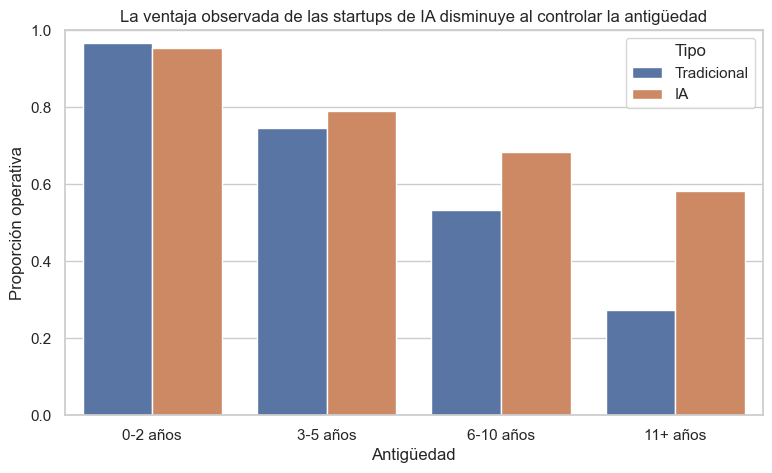

In [49]:
plt.figure(figsize=(9,5))

sns.barplot(

    data=comparacion,

    x="tramo_antiguedad",

    y="is_operating",

    hue="grupo"

)

plt.ylim(0,1)

plt.xlabel(
    "Antigüedad"
)

plt.ylabel(
    "Proporción operativa"
)
plt.title(
    "La ventaja observada de las startups de IA disminuye al controlar la antigüedad"
)

plt.legend(
    title="Tipo"
)

plt.show()

### Análisis Figura 3: La ventaja observada de las startups de IA disminuye al controlar la antigüedad

Al comparar startups de IA y tradicionales dentro de los mismos tramos de antigüedad, la diferencia observada inicialmente se reduce considerablemente, especialmente en las empresas más recientes. Esto sugiere que parte de la ventaja observada en la Figura 1 puede explicarse por la distribución de edades de las startups, ya que las empresas de IA tienden a concentrarse en batches más recientes. Aun así, en algunos tramos la diferencia continúa siendo favorable para las startups de IA.

# Pregunta 4
¿Existen diferencias en la permanencia operativa según la industria de las startups?

In [50]:
industria = (

    df
    .groupby("industry")
    ["is_operating"]
    .mean()
    .sort_values(
        ascending=False
    )
    .reset_index()

)

industria

,industry,is_operating
0,Unspecified,0.944444
1,Industrials,0.825991
2,Healthcare,0.777618
3,Government,0.772727
4,Fintech,0.741985
5,B2B,0.714105
6,Education,0.691057
7,Real Estate and Construction,0.625767
8,Consumer,0.473982


C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Casti\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


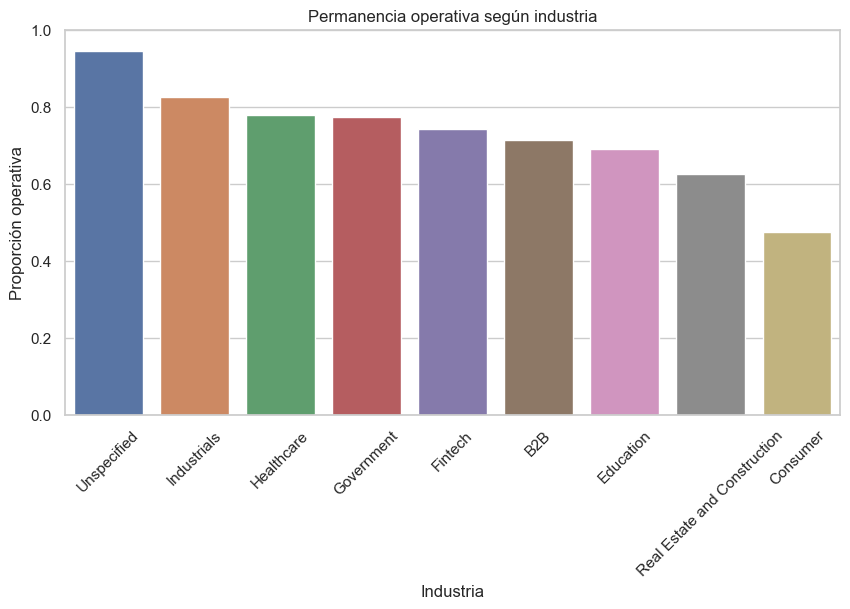

In [51]:
plt.figure(figsize=(10,5))

sns.barplot(

    data=industria,

    x="industry",

    y="is_operating"

)

plt.ylim(0,1)

plt.xticks(rotation=45)

plt.xlabel(
    "Industria"
)

plt.ylabel(
    "Proporción operativa"
)

plt.title(
    "Permanencia operativa según industria"
)

plt.show()

### Análisis Figura 4: La permanencia operativa varía según la industria
Se observan diferencias relevantes entre industrias. Las startups pertenecientes a sectores como Industrials, Healthcare y Government presentan mayores tasas de permanencia operativa, mientras que las empresas orientadas al consumidor muestran los valores más bajos. Estos resultados sugieren que el sector económico podría estar asociado con distintas probabilidades de permanencia operativa dentro del ecosistema de Y Combinator.

# Hallazgo Principal

De las variables analizadas, la antigüedad de la startup parece ser el factor más fuertemente asociado con la permanencia operativa. Asimismo, se observan diferencias entre industrias y una ventaja inicial de las startups relacionadas con inteligencia artificial, aunque parte de esta diferencia disminuye al controlar la antigüedad de las empresas.